# Estimativa de Remuneração na Paraíba
## Estimativa de remuneração mensal de referência na Paraíba

Estudante: Vivian Germano da Silva  
Matrícula: 20240045345  
Componente curricular: Aprendizado de Máquina Supervisionado  
Base: RAIS 2025, vínculos formais de trabalho  
Semente individual: 045345 (valor inteiro utilizado no código: `45345`)

> Este notebook documenta a construção de um modelo de regressão para estimar uma remuneração mensal de referência de vínculos formais de trabalho na Paraíba. O conjunto de teste permanece reservado até o congelamento das decisões de modelagem.

## 0. Identificação e semente

A semente individual corresponde aos seis últimos dígitos da matrícula: 045345. Para as operações aleatórias, o valor inteiro utilizado é `45345`.

A separação treino/teste já foi realizada de forma reprodutível. A amostra individual de 2.000 observações foi retirada exclusivamente do conjunto de treino. O conjunto de teste está reservado para a avaliação final.

In [1]:
MATRICULA = "20240045345"
SEMENTE = int(MATRICULA[-6:])
SEMENTE_PARTICAO = 42

print("Matrícula:", MATRICULA)
print("Semente individual:", MATRICULA[-6:])
print("Valor inteiro da semente:", SEMENTE)

Matrícula: 20240045345
Semente individual: 045345
Valor inteiro da semente: 45345


## 1. Usuário, decisão e tipo de problema

Escolhi o SINE como possível usuário do modelo, porque o serviço orienta pessoas que estão procurando emprego e pode precisar de informações para conversar sobre remuneração.

A decisão que o modelo poderia apoiar seria apresentar uma estimativa de remuneração histórica como referência para uma ocupação e uma localidade. A previsão seria feita depois que a ocupação pretendida ou a ocupação da vaga e o município do estabelecimento já estivessem definidos, além das informações de idade e escolaridade. Se essas informações ainda não estiverem disponíveis, não considero adequado apresentar a estimativa como se fosse específica para aquela oportunidade.

A pergunta que orientou o trabalho foi: é possível estimar a remuneração mensal de referência de vínculos formais de trabalho na Paraíba usando características profissionais e sociodemográficas, de modo a apoiar a orientação de candidatos pelo SINE?

Decidi trabalhar com regressão porque a variável que quero estimar é numérica e está expressa em reais. Assim, o resultado pode ser apresentado como um valor de referência, em vez de classificar a remuneração em faixas.

A principal métrica escolhida foi a MAE em reais. Entendo que ela facilita a interpretação do erro, porque mostra, em média, quantos reais a previsão ficou distante do valor observado. Um erro para cima pode criar uma expectativa salarial maior do que a remuneração praticada, enquanto um erro para baixo pode desvalorizar a qualificação do candidato. A MAE não mostra a direção do erro, mas permite avaliar a distância média entre previsão e valor observado.

É importante destacar que o modelo não prevê se a pessoa será contratada, se existe vaga disponível ou qual salário um empregador necessariamente oferecerá. A proposta é oferecer apenas uma referência baseada nos vínculos formais observados na RAIS.

## 2. Atributos e codificação

A variável que pretendo estimar é `Remuneracao`, correspondente à remuneração nominal de dezembro (`Vl Rem Dezembro Nom`) dos vínculos ativos em 31/12/2025, considerando somente valores positivos.

| Atributo | Disponível no momento do uso? | Sinal esperado | Por que considerei esse atributo | Risco e forma de tratamento |
|---|---|---|---|---|
| `Idade` | Em princípio, pode ser informada no cadastro do candidato. | Pode ter associação positiva em parte da trajetória, mas não necessariamente de forma linear. | Pode representar parcialmente a experiência acumulada, embora idade não seja a mesma coisa que experiência profissional. | Foi tratada como variável numérica. Uma relação linear pode não representar todas as trajetórias e a idade pode refletir diferenças geracionais. |
| `Escolaridade` | Pode ser informada pelo candidato durante o atendimento. | Em geral, espero uma associação positiva. | A escolaridade pode ampliar o acesso a determinadas ocupações e funções com remunerações maiores. | Foi tratada como categórica por meio de one-hot encoding, sem assumir que a distância entre os códigos seja igual. Categorias pouco frequentes podem gerar estimativas menos estáveis. |
| `CBO`, dois primeiros dígitos | Só está disponível quando a ocupação pretendida ou a ocupação da vaga já estiver definida. | A associação varia conforme o grande grupo ocupacional. | As ocupações possuem exigências, responsabilidades e estruturas de remuneração diferentes. | Usei os dois primeiros dígitos para reduzir a quantidade de categorias. Isso facilita o processamento, mas também elimina detalhes da ocupação. |
| Município do estabelecimento | Só fica definido quando a localidade da oportunidade é conhecida. | A associação varia conforme o mercado de trabalho de cada município. | As remunerações podem mudar de acordo com a atividade econômica e as condições locais. | Foi tratado como categórico, com `min_frequency=10` para agrupar categorias pouco frequentes. O código representa o município do estabelecimento, não a residência do candidato. |

Mantive `Sexo` na base para comparar os erros entre grupos, mas não utilizei essa informação como preditora. Fiz essa escolha para não usar diretamente uma característica sensível na estimativa individual. Mesmo assim, reconheço que outras variáveis, como ocupação, escolaridade e município, podem refletir desigualdades existentes.

Também evitei utilizar como preditoras variáveis que fossem calculadas a partir da própria remuneração. O pré-processamento dos modelos, incluindo a codificação das categorias, foi colocado dentro dos pipelines para que seja ajustado durante cada etapa da validação, sem aproveitar informações das partições de validação.

Um ponto que considero importante para a aplicação prática é que a ocupação e o município precisam estar realmente definidos no atendimento. Não seria adequado utilizar uma ocupação presumida ou o município de residência como se fossem os dados da vaga. Além disso, as associações encontradas não significam que esses atributos causem mudanças na remuneração. Outros fatores, como experiência, jornada, setor e empregador, também influenciam os valores e não estão completamente representados no modelo.

## 3. Amostra, partição e validação

A base analítica foi construída a partir dos microdados da RAIS 2025 para a Paraíba. Foram considerados vínculos ativos em 31/12/2025 e remuneração nominal de dezembro positiva. Registros sem remuneração de dezembro foram excluídos.

A base filtrada contém 764.753 vínculos. A partição foi feita em 80% para treino e 20% para teste. A amostra individual de 2.000 observações foi retirada apenas do conjunto de treino, com a semente individual `45345`.

O conjunto de teste possui 152.951 registros e não deve ser usado para escolher atributos, modelos ou hiperparâmetros. A seleção e a validação dos modelos ocorrerão dentro da amostra de treino, com validação cruzada.

In [2]:
# Localiza a pasta principal do projeto, tanto se o Jupyter for aberto
# na raiz do projeto quanto se for aberto dentro da pasta notebook.
from pathlib import Path

candidatos = [Path.cwd(), Path.cwd().parent]
RAIZ = next(
    (p.resolve() for p in candidatos
     if (p / "data" / "processed" / "Dtreino_Vivian.csv").exists()),
    None
)
if RAIZ is None:
    raise FileNotFoundError(
        "Não encontrei data/processed/Dtreino_Vivian.csv. "
        "Abra o Jupyter na pasta do projeto ou na pasta notebook."
    )

PASTA_DADOS = RAIZ / "data" / "processed"
ARQ_DTREINO = PASTA_DADOS / "Dtreino_Vivian.csv"
ARQ_TESTE = PASTA_DADOS / "teste_reservado_Vivian.csv"

print("Pasta do projeto:", RAIZ)
print("Amostra de treino:", ARQ_DTREINO)
print("Conjunto de teste reservado:", ARQ_TESTE)

Pasta do projeto: C:\Users\vivia\OneDrive\Área de Trabalho\remunerometro
Amostra de treino: C:\Users\vivia\OneDrive\Área de Trabalho\remunerometro\data\processed\Dtreino_Vivian.csv
Conjunto de teste reservado: C:\Users\vivia\OneDrive\Área de Trabalho\remunerometro\data\processed\teste_reservado_Vivian.csv


In [3]:
import numpy as np
import pandas as pd

df = pd.read_csv(ARQ_DTREINO)

alvo = "Remuneracao"
coluna_sexo = "Sexo - Código"
coluna_cbo = "CBO 2002 Ocupação - Código"
coluna_escolaridade = "Escolaridade Após 2005 - Código"
coluna_municipio = "Município - Código"

preditores = [
    "Idade",
    coluna_escolaridade,
    coluna_cbo,
    coluna_municipio
]

X = df[preditores].copy()
y = df[alvo].astype(float).copy()
sexo = df[coluna_sexo].copy()

print("Observações na amostra:", len(df))
print("Preditores originais:", len(preditores))
print("Remuneração mínima:", y.min())
print("Remuneração mediana:", y.median())
print("Remuneração máxima:", y.max())
print("Valores ausentes na amostra:", int(df[preditores + [alvo, coluna_sexo]].isna().sum().sum()))

Observações na amostra: 2000
Preditores originais: 4
Remuneração mínima: 455.4
Remuneração mediana: 2110.455
Remuneração máxima: 50089.02
Valores ausentes na amostra: 0


### Dimensão após a codificação

A codificação one-hot foi examinada previamente na amostra individual. O resultado foi n = 2.000, p = 55 colunas após a transformação e p/n = 0,0275. O número de colunas codificadas é maior do que o número de atributos originais porque as variáveis categóricas são representadas por indicadores.

A contagem será novamente conferida no pipeline usado para os modelos.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline

def reduzir_cbo(X):
    # Mantém os dois primeiros dígitos da classificação CBO.
    return pd.DataFrame(X).astype(str).apply(lambda coluna: coluna.str[:2])

preprocessador = ColumnTransformer(
    transformers=[
        ("idade", StandardScaler(), ["Idade"]),
        ("escolaridade",
         OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10),
         [coluna_escolaridade]),
        ("cbo",
         Pipeline(steps=[
             ("reduzir", FunctionTransformer(reduzir_cbo, validate=False)),
             ("onehot", OneHotEncoder(
                 handle_unknown="infrequent_if_exist",
                 min_frequency=10
             ))
         ]),
         [coluna_cbo]),
        ("municipio",
         OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10),
         [coluna_municipio])
    ],
    remainder="drop"
)

X_codificado = preprocessador.fit_transform(X)
n, p = X_codificado.shape

print("Número de observações (n):", n)
print("Número de atributos após One-Hot (p):", p)
print("Razão p/n:", round(p / n, 4))
print("Dimensão da matriz:", X_codificado.shape)

Número de observações (n): 2000
Número de atributos após One-Hot (p): 55
Razão p/n: 0.0275
Dimensão da matriz: (2000, 55)


## 4. Modelos e hiperparâmetros

Comparei quatro alternativas para entender se os modelos mais elaborados conseguiriam melhorar a estimativa em relação a uma previsão simples:

1. Baseline: utiliza a mediana da remuneração observada no treino.
2. OLS/MQO: regressão linear sem penalização.
3. Ridge: regressão com penalização L2.
4. Lasso: regressão com penalização L1.

Como a remuneração apresenta uma distribuição assimétrica, os modelos foram ajustados usando `log1p(Remuneracao)`. Depois, as previsões são convertidas novamente para reais. Para comparar os modelos, usei a MAE em reais como métrica principal, porque consigo interpretar o resultado diretamente como uma diferença média em dinheiro. Também apresento a RMSE na escala logarítmica como medida complementar.

A validação cruzada foi feita com cinco partições, utilizando embaralhamento e a semente individual. Para Ridge e Lasso, testei valores de `alpha` entre 0,0001 e 10.000, distribuídos em escala logarítmica. O melhor valor encontrado para Ridge foi 1,0 e, para Lasso, 0,001.

O valor escolhido para o Lasso ficou dentro da grade, mas relativamente próximo do limite inferior. Por isso, considero que essa região poderia ser investigada com mais detalhe em uma próxima etapa. Não fiz esse ajuste usando o conjunto de teste, pois ele deve permanecer reservado para a avaliação final.

O `alpha` controla a intensidade da penalização. Quando aumenta, os coeficientes são mais restringidos. A escolha foi feita pela menor MAE média na validação cruzada, e não pelo menor erro observado nos dados de treino.

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, GridSearchCV, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, make_scorer

def criar_modelo(regressor):
    pipeline = Pipeline(steps=[
        ("preprocessamento", preprocessador),
        ("regressao", regressor)
    ])
    return TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1
    )

def mae_reais(y_true, y_pred):
    return mean_absolute_error(y_true, y_pred)

def rmse_log(y_true, y_pred):
    y_pred_seguro = np.maximum(y_pred, 0)
    return np.sqrt(mean_squared_error(
        np.log1p(y_true),
        np.log1p(y_pred_seguro)
    ))

pontuacao = {
    "mae_reais": make_scorer(mae_reais, greater_is_better=False),
    "rmse_log": make_scorer(rmse_log, greater_is_better=False)
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)

modelo_baseline = criar_modelo(DummyRegressor(strategy="median"))
modelo_ols = criar_modelo(LinearRegression())
modelo_ridge_base = criar_modelo(Ridge(solver="lsqr"))
modelo_lasso_base = criar_modelo(Lasso(max_iter=30000, tol=1e-4))

grade_alpha = np.logspace(-4, 4, 17)

print("Validação cruzada: 5 partições")
print("Grade de alpha:", grade_alpha)

Validação cruzada: 5 partições
Grade de alpha: [1.00000000e-04 3.16227766e-04 1.00000000e-03 3.16227766e-03
 1.00000000e-02 3.16227766e-02 1.00000000e-01 3.16227766e-01
 1.00000000e+00 3.16227766e+00 1.00000000e+01 3.16227766e+01
 1.00000000e+02 3.16227766e+02 1.00000000e+03 3.16227766e+03
 1.00000000e+04]


In [6]:
# Ajuste dos hiperparâmetros com validação cruzada de cinco partições.
busca_ridge = GridSearchCV(
    estimator=modelo_ridge_base,
    param_grid={"regressor__regressao__alpha": grade_alpha},
    scoring=make_scorer(mae_reais, greater_is_better=False),
    cv=cv,
    n_jobs=-1,
    refit=True
)
busca_lasso = GridSearchCV(
    estimator=modelo_lasso_base,
    param_grid={"regressor__regressao__alpha": grade_alpha},
    scoring=make_scorer(mae_reais, greater_is_better=False),
    cv=cv,
    n_jobs=-1,
    refit=True
)

busca_ridge.fit(X, y)
busca_lasso.fit(X, y)

print("Melhor alpha Ridge:", busca_ridge.best_params_["regressor__regressao__alpha"])
print("MAE CV Ridge:", -busca_ridge.best_score_)
print("Melhor alpha Lasso:", busca_lasso.best_params_["regressor__regressao__alpha"])
print("MAE CV Lasso:", -busca_lasso.best_score_)

Melhor alpha Ridge: 1.0
MAE CV Ridge: 1678.5075518070457
Melhor alpha Lasso: 0.001
MAE CV Lasso: 1678.383293394188


## 5. Diagnóstico de sobreajuste

Para avaliar se os modelos estavam se ajustando demais aos dados de treino, comparei o erro de treino com a média e o desvio-padrão dos erros obtidos na validação cruzada. Quando o erro de treino é muito menor que o de validação, pode existir sobreajuste. Quando os dois erros são altos, pode haver subajuste.

Também observei a curva de validação do Lasso. Ela ajuda a visualizar o que acontece quando a penalização aumenta: valores muito pequenos deixam o modelo mais flexível, enquanto valores muito altos podem restringir demais os coeficientes.

Na amostra, obtive 2.000 observações e 55 colunas depois da codificação, resultando em `p/n = 0,0275`. Essa relação é relativamente baixa, mas não significa que o modelo esteja automaticamente livre de sobreajuste. A frequência das categorias e a variação das remunerações também precisam ser consideradas. O agrupamento de categorias com frequência inferior a 10 ajuda a reduzir a instabilidade, mas pode esconder diferenças entre ocupações e municípios.

In [7]:
# Comparação de desempenho na amostra de treino e na validação cruzada.
modelos = {
    "Baseline mediana": modelo_baseline,
    "OLS/MQO": modelo_ols,
    "Ridge selecionado": busca_ridge.best_estimator_,
    "Lasso selecionado": busca_lasso.best_estimator_
}

linhas = []
for nome, modelo in modelos.items():
    cv_resultado = cross_validate(
        modelo, X, y, cv=cv, scoring=pontuacao,
        return_train_score=True, n_jobs=-1
    )
    modelo.fit(X, y)
    pred_treino = modelo.predict(X)

    linhas.append({
        "Modelo": nome,
        "MAE treino (R$)": mean_absolute_error(y, pred_treino),
        "MAE CV média (R$)": -cv_resultado["test_mae_reais"].mean(),
        "MAE CV desvio (R$)": cv_resultado["test_mae_reais"].std(),
        "RMSE log treino": rmse_log(y, pred_treino),
        "RMSE log CV média": -cv_resultado["test_rmse_log"].mean(),
        "RMSE log CV desvio": cv_resultado["test_rmse_log"].std()
    })

tabela_modelos = pd.DataFrame(linhas)
display(tabela_modelos.round(4))

,Modelo,MAE treino (R$),MAE CV média (R$),MAE CV desvio (R$),RMSE log treino,RMSE log CV média,RMSE log CV desvio
0,Baseline mediana,1939.1585,1939.8192,227.7453,0.7192,0.7178,0.0522
1,OLS/MQO,1630.3050,1684.8962,201.5575,0.5408,0.5575,0.0321
2,Ridge selecionado,1632.3912,1678.5076,202.7579,0.5409,0.5568,0.0322
3,Lasso selecionado,1639.7158,1678.3833,205.2511,0.5430,0.5562,0.0328


,Alpha,MAE treino,MAE validação
0,0.00,1626.47,1683.36
1,0.00,1627.68,1680.46
2,0.00,1634.90,1678.38
3,0.00,1665.99,1698.84
4,0.01,1723.95,1733.88
5,0.03,1772.58,1777.53
6,0.10,1913.39,1916.40
7,0.32,2011.04,2011.91
8,1.00,2011.04,2011.91
9,3.16,2011.04,2011.91


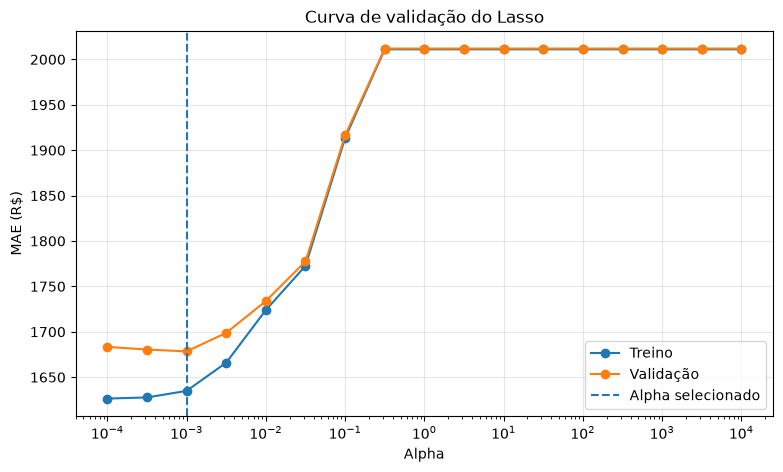

In [8]:
from sklearn.model_selection import validation_curve
import matplotlib.pyplot as plt

alphas_curva = np.logspace(-4, 4, 17)

treino_scores, validacao_scores = validation_curve(
    modelo_lasso_base,
    X,
    y,
    param_name="regressor__regressao__alpha",
    param_range=alphas_curva,
    cv=cv,
    scoring=make_scorer(mae_reais, greater_is_better=False),
    n_jobs=-1
)

erro_treino = -treino_scores.mean(axis=1)
erro_validacao = -validacao_scores.mean(axis=1)

tabela_curva = pd.DataFrame({
    "Alpha": alphas_curva,
    "MAE treino": erro_treino,
    "MAE validação": erro_validacao
})

display(tabela_curva.round(2))

plt.figure(figsize=(9, 5))
plt.semilogx(alphas_curva, erro_treino, marker="o", label="Treino")
plt.semilogx(alphas_curva, erro_validacao, marker="o", label="Validação")
plt.axvline(0.001, linestyle="--", label="Alpha selecionado")
plt.xlabel("Alpha")
plt.ylabel("MAE (R$)")
plt.title("Curva de validação do Lasso")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Como interpretei a curva de validação do Lasso

Na curva, o menor erro de validação aparece em `alpha = 0,001`, que também foi o valor escolhido pela busca de hiperparâmetros. Nesse ponto, a MAE média da validação cruzada ficou em aproximadamente R$ 1.678,38.

Nos valores menores de `alpha`, a diferença entre o erro de treino e o de validação é pequena. Por isso, não identifiquei um sinal forte de sobreajuste nessa região. Conforme a penalização aumenta, os erros também aumentam. A partir de aproximadamente `alpha = 0,3`, a elevação fica mais evidente e depois os valores se estabilizam perto de R$ 2.010.

Minha interpretação é que, nesse trecho, a penalização começa a limitar demais o modelo e ele passa a apresentar subajuste. Assim, entre os valores testados, `alpha = 0,001` apresentou o melhor equilíbrio entre o ajuste aos dados de treino e o desempenho na validação cruzada.

## 6. Avaliação no teste e escolha final

Depois de definir os atributos, o pré-processamento, os modelos e os hiperparâmetros com os dados de treino e a validação cruzada, utilizei o conjunto de teste para avaliar o desempenho final.

A tabela desta seção apresenta a MAE em reais e a RMSE na escala logarítmica para os quatro modelos. A escolha do modelo não foi feita com base no resultado do teste. Antes de abrir essa base, o critério definido foi selecionar o modelo com a menor MAE média na validação cruzada. Portanto, o teste serve para verificar como essa escolha se comporta em dados que ficaram reservados.

In [9]:
# CONJUNTO DE TESTE: abrir uma única vez, após congelar todas as decisões anteriores.
teste = pd.read_csv(ARQ_TESTE)

X_teste = teste[preditores].copy()
y_teste = teste[alvo].astype(float).copy()

# Os quatro modelos já foram ajustados em todo o Dtreino na célula de comparação.
# Aqui apenas avaliamos cada modelo no teste reservado, sem reajuste ou seleção.
linhas_teste = []
predicoes_teste = {}

for nome, modelo in modelos.items():
    previsoes = modelo.predict(X_teste)
    predicoes_teste[nome] = previsoes

    linhas_teste.append({
        "Modelo": nome,
        "MAE teste (R$)": mean_absolute_error(y_teste, previsoes),
        "RMSE log teste": rmse_log(y_teste, previsoes)
    })

tabela_teste = pd.DataFrame(linhas_teste)
display(tabela_teste.round(4))

# A escolha final continua baseada exclusivamente na MAE média da validação cruzada.
nome_final = tabela_modelos.loc[
    tabela_modelos["MAE CV média (R$)"].idxmin(), "Modelo"
]
modelo_final = modelos[nome_final]
pred_teste = predicoes_teste[nome_final]

print("Modelo selecionado pela MAE média de CV:", nome_final)
print("MAE no teste (R$):", round(mean_absolute_error(y_teste, pred_teste), 2))
print("RMSE log no teste:", round(rmse_log(y_teste, pred_teste), 4))


,Modelo,MAE teste (R$),RMSE log teste
0,Baseline mediana,1964.2017,0.7194
1,OLS/MQO,1648.3676,0.5413
2,Ridge selecionado,1650.9168,0.5412
3,Lasso selecionado,1654.9512,0.5410


Modelo selecionado pela MAE média de CV: Lasso selecionado
MAE no teste (R$): 1654.95
RMSE log no teste: 0.541


### Erros por grupo: escolaridade e sexo

Também comparei os erros por escolaridade e sexo para observar se o modelo apresenta dificuldades diferentes entre os grupos. `Sexo` não entrou como variável preditora, mas foi mantido para essa verificação.

Essa comparação é importante porque uma média geral pode esconder erros maiores em determinados grupos. Ao mesmo tempo, uma diferença entre as métricas não prova, sozinha, que exista discriminação. É necessário considerar a composição das ocupações, as diferenças de remuneração e as limitações dos dados.

In [10]:

def resumo_erro_grupo(dados, y_real, y_previsto, coluna):
    escolaridade = {
        "1": "Analfabeto",
        "2": "Ate 5\u00aa serie incompleta",
        "3": "5\u00aa serie completa",
        "4": "6\u00aa a 9\u00aa serie incompleta",
        "5": "Fundamental completo",
        "6": "Medio incompleto",
        "7": "Medio completo",
        "8": "Superior incompleto",
        "9": "Superior completo",
        "10": "Mestrado",
        "11": "Doutorado"
    }

    sexo = {
        "1": "Masculino",
        "2": "Feminino"
    }

    resultado = dados[[coluna]].copy()
    resultado["real"] = np.asarray(y_real)
    resultado["previsto"] = np.asarray(y_previsto)

    linhas = []

    for grupo, parte in resultado.groupby(coluna, dropna=False):
        codigo_grupo = str(int(grupo)) if isinstance(grupo, (int, float, np.integer, np.floating)) and pd.notna(grupo) and float(grupo).is_integer() else str(grupo)

        if "Escolaridade" in coluna:
            rotulo = escolaridade.get(codigo_grupo, f"Codigo {codigo_grupo}")
        elif "Sexo" in coluna:
            rotulo = sexo.get(codigo_grupo, f"Codigo {codigo_grupo}")
        else:
            rotulo = f"Codigo {codigo_grupo}"

        linhas.append({
            "Grupo": rotulo,
            "Codigo original": grupo,
            "n": len(parte),
            "MAE (R$)": mean_absolute_error(parte["real"], parte["previsto"]),
            "RMSE log": rmse_log(parte["real"], parte["previsto"])
        })

    return pd.DataFrame(linhas).sort_values("n", ascending=False).reset_index(drop=True)


display(resumo_erro_grupo(teste, y_teste, pred_teste, coluna_escolaridade))
display(resumo_erro_grupo(teste, y_teste, pred_teste, coluna_sexo))


,Grupo,Codigo original,n,MAE (R$),RMSE log
0,Medio completo,7,79237,869.569464,0.432991
1,Superior completo,9,40770,3332.288053,0.733250
2,Fundamental completo,5,7521,773.589925,0.400774
3,Medio incompleto,6,5645,722.895948,0.415916
4,6ª a 9ª serie incompleta,4,5007,734.119397,0.394703
5,Superior incompleto,8,4376,1085.056397,0.501302
6,Ate 5ª serie incompleta,2,3446,715.506775,0.379646
7,5ª serie completa,3,2333,1028.268804,0.520427
8,Mestrado,10,1979,5431.419707,0.802818
9,Analfabeto,1,1602,2700.263747,0.689530


,Grupo,Codigo original,n,MAE (R$),RMSE log
0,Masculino,1,86666,1631.472820,0.536089
1,Feminino,2,66285,1685.648688,0.547372


### O que observei nos erros por grupo

Na comparação por escolaridade, encontrei diferenças consideráveis entre os grupos. As maiores MAEs apareceram entre pessoas com doutorado (R$ 9.763,22), mestrado (R$ 5.431,42) e superior completo (R$ 3.332,29). Isso mostra que, nesses grupos, o modelo ficou mais distante dos valores observados. O RMSE na escala logarítmica também foi maior nesses segmentos.

As menores MAEs foram observadas entre pessoas com escolaridade até a 5ª série incompleta (R$ 715,51), ensino médio incompleto (R$ 722,90) e escolaridade de 6ª a 9ª série incompleta (R$ 734,12). Porém, não interpreto esses números como prova de que o modelo funciona melhor em todos os sentidos para esses grupos. Os valores e a dispersão das remunerações podem ser diferentes entre eles, e a MAE é uma medida em reais.

Na comparação por sexo, a MAE foi de R$ 1.631,47 no grupo masculino e R$ 1.685,65 no feminino. A diferença foi de R$ 54,18. O RMSE logarítmico também ficou um pouco maior no grupo feminino (0,547, contra 0,536).

Esses resultados chamaram minha atenção porque mostram que o erro não se distribui exatamente da mesma maneira entre todos os grupos. Mesmo assim, não posso concluir apenas com esses números que o modelo esteja discriminando. A análise é agregada e não controla todas as diferenças profissionais e sociodemográficas. Reforço também que `Sexo` não foi usado para gerar as previsões, apenas para comparar os erros.

Com essa análise, entendo que a estimativa precisa ser apresentada com cuidado, como uma referência histórica, e não como um salário garantido ou como critério automático para selecionar candidatos. Os valores descritos aqui devem ser conferidos depois da execução atualizada do notebook.

### Como foi feita a escolha do modelo

O critério utilizado para escolher os hiperparâmetros foi a menor MAE média nas cinco partições da validação cruzada:

$$
\widehat{MAE}_{CV}(\alpha)=\frac{1}{5}\sum_{k=1}^{5}
\frac{1}{n_k}\sum_{i\in V_k}|y_i-\hat y_i^{(-k,\alpha)}|.
$$

Em termos práticos, calculei a diferença absoluta entre o valor observado e o previsto em cada partição e depois considerei a média dos resultados. Para Ridge, a penalização é L2; para Lasso, é L1. O parâmetro `alpha` controla o peso dessa penalização: quanto maior o valor, maior a restrição sobre os coeficientes. Depois da comparação na validação cruzada, o conjunto de teste ficou reservado para avaliar o desempenho final.

## 7. Limitações, riscos e declaração de uso de IA

### Limitações e riscos que considerei

- A RAIS reúne vínculos formais declarados e, por isso, não representa todo o mercado de trabalho, especialmente os vínculos informais.
- A remuneração de dezembro de 2025 é um dado histórico e não garante que uma vaga futura ofereça o mesmo valor.
- A base contém vínculos de trabalho, não necessariamente pessoas únicas. Uma pessoa pode ter mais de um vínculo.
- O município utilizado é o do estabelecimento informado na RAIS, e não o município de residência do trabalhador.
- A redução da CBO para os dois primeiros dígitos diminui a quantidade de categorias, mas também retira detalhes sobre a ocupação.
- A amostra individual de 2.000 registros pode representar pouco algumas categorias raras.
- Para usar o modelo no atendimento, seria necessário ter a ocupação e o município da oportunidade definidos.
- Não considero adequado usar a estimativa sozinha para selecionar, excluir ou classificar candidatos.
- As diferenças de erro entre grupos precisam ser acompanhadas, pois o modelo pode reproduzir desigualdades que já aparecem nos dados.

### Declaração de uso de inteligência artificial

Utilizei o ChatGPT como ferramenta de apoio para esclarecer conceitos de aprendizagem de máquina, organizar as etapas do trabalho, revisar a redação de algumas partes e ajudar a elaborar e corrigir trechos de código. O apoio influenciou a documentação da formulação do problema, da escolha dos atributos, da validação, da comparação dos modelos, da avaliação e das limitações, além de partes do código de preparação e análise.

As decisões finais e a interpretação dos resultados são de minha responsabilidade. É importante registrar que a ferramenta foi utilizada como apoio, e não como substituta da análise. Revisei o material e preciso conseguir explicar as escolhas, os procedimentos e os resultados apresentados no notebook.

## Registro final de execução

### Resultados principais

Os valores apresentados nesta seção correspondem aos resultados registrados na execução do notebook.

- Amostra individual: 2.000 observações.
- Colunas após a codificação: 55.
- Semente individual: 45345.
- Modelo selecionado pela menor MAE média na validação cruzada: Lasso.
- Melhor hiperparâmetro do Lasso: `alpha = 0,001`.
- MAE média na validação cruzada: aproximadamente R$ 1.678,38.
- MAE no conjunto de teste: R$ 1.654,95.
